In [2]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    recall_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

import xgboost as xgb
import lightgbm as lgb

In [ ]:
df = pd.read_csv('..data/cleaned_data.csv')

X = df.drop(columns=['Response'])
y = df['Response']

print("Shape:", df.shape)
print("Class distribution:\n", y.value_counts(normalize=True).round(3))

Shape: (381109, 13)
Class distribution:
 Response
0    0.877
1    0.123
Name: proportion, dtype: float64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (304887, 12) | Test: (76222, 12)


In [5]:
num_cols = [
    'Age',
    'Annual_Premium',
    'Vintage',
    'Region_Code',
    'Policy_Sales_Channel'
]

scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols]  = scaler.transform(X_test[num_cols])

print("Scaling done.")

Scaling done.


In [6]:
# Class imbalance weight (no. negatives / no. positives)
neg, pos = y_train.value_counts()[0], y_train.value_counts()[1]
scale = neg / pos
print(f"scale_pos_weight: {scale:.2f}  (neg={neg}, pos={pos})")

# XGBoost
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=scale,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42
)
xgb_model.fit(X_train, y_train)
print("XGBoost trained.")

# LightGBM
lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    class_weight='balanced',
    random_state=42
)
lgb_model.fit(X_train, y_train)
print("LightGBM trained.")

scale_pos_weight: 7.16  (neg=267519, pos=37368)


c:\Users\saart\Desktop\323_MAI\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [17:19:31] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost trained.
[LightGBM] [Info] Number of positive: 37368, number of negative: 267519
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009294 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 742
[LightGBM] [Info] Number of data points in the train set: 304887, number of used features: 12
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positiv


  XGBoost
  Accuracy  : 0.7070
  F1 Score  : 0.4356
  ROC-AUC   : 0.8578
  Recall    : 0.9226

  Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.68      0.80     66880
           1       0.29      0.92      0.44      9342

    accuracy                           0.71     76222
   macro avg       0.63      0.80      0.62     76222
weighted avg       0.90      0.71      0.76     76222



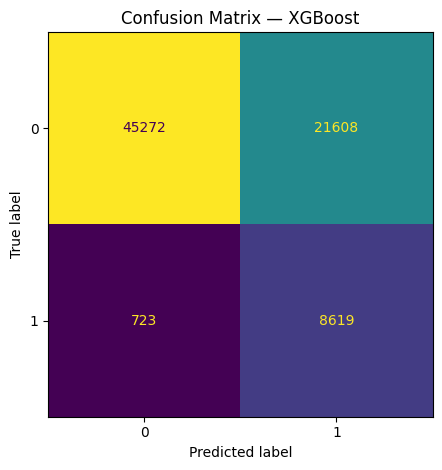


  LightGBM
  Accuracy  : 0.7075
  F1 Score  : 0.4362
  ROC-AUC   : 0.8578
  Recall    : 0.9231

  Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.68      0.80     66880
           1       0.29      0.92      0.44      9342

    accuracy                           0.71     76222
   macro avg       0.63      0.80      0.62     76222
weighted avg       0.90      0.71      0.76     76222



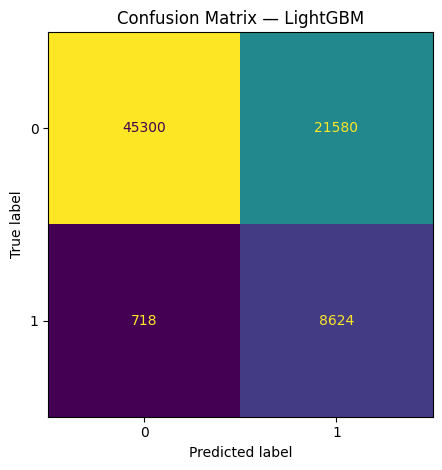

In [7]:
models = {
    "XGBoost"  : xgb_model,
    "LightGBM" : lgb_model,
}

results = []

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    acc    = accuracy_score(y_test, y_pred)
    f1     = f1_score(y_test, y_pred)
    auc    = roc_auc_score(y_test, y_prob)
    recall = recall_score(y_test, y_pred)

    print(f"\n{'='*45}")
    print(f"  {name}")
    print(f"{'='*45}")
    print(f"  Accuracy  : {acc:.4f}")
    print(f"  F1 Score  : {f1:.4f}")
    print(f"  ROC-AUC   : {auc:.4f}")
    print(f"  Recall    : {recall:.4f}")
    print(f"\n  Classification Report:\n")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm).plot(colorbar=False)
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

    results.append([name, 0.5, acc, f1, auc, recall])

In [9]:
results_df = pd.DataFrame(
    results,
    columns=["Model", "Threshold", "Accuracy", "F1 Score", "ROC-AUC", "Recall"]
)

results_df.style.highlight_max(
    subset=["F1 Score", "ROC-AUC", "Recall"],
    color="lightgreen"
)

,Model,Threshold,Accuracy,F1 Score,ROC-AUC,Recall
0,XGBoost,0.500000,0.707027,0.435644,0.857792,0.922608
1,LightGBM,0.500000,0.707460,0.436150,0.857818,0.923143


In [ ]:
joblib.dump(xgb_model, '..exports/xgb_model.sav')
joblib.dump(lgb_model, '..exports/lgb_model.sav')

print("Models saved.")

Models saved.
